# Early prediction on the full event sets

10,000 IEEE 9-bus and 7,999 New England events (PowerFactory RMS simulations), streamed shard by shard. Windows are measured from fault inception. Every model is evaluated on the same 5-fold split, repeated 3 times; intervals are corrected resampled-t 95 % intervals.

Set `TRANPY_SHARDS_DIR` to a folder with one sub-folder of shards per system, or leave it unset to stream the published release.

In [1]:
import logging, os, warnings
import numpy as np
import pandas as pd
import tranpy
from tranpy.early_prediction import evaluate_window_tables, extract_window_tables, find_knee_point
from tranpy.plotting import plot_early_prediction
from tranpy_core.models import make_pipeline
from pathlib import Path
import matplotlib.pyplot as plt
from tranpy_core.plotting import publication_style, save_figure

FIGURES = Path("outputs")
plt.rcParams["figure.dpi"] = 150

warnings.filterwarnings("ignore", category=FutureWarning)
SHARDS = os.environ.get("TRANPY_SHARDS_DIR")
CACHE = Path.home() / "tranpy-data" / "cache" / "tables"
WINDOWS = (0.05, 0.1, 0.2, 0.4, 0.8)
SYSTEMS = ("ieee_9bus", "new_england")
FIGURES.mkdir(exist_ok=True)
logging.basicConfig(filename=FIGURES / "08_progress.log", level=logging.INFO, format="%(asctime)s %(message)s", force=True)

## Data

In [2]:
sources = {s: tranpy.open_event_shards(s, source=Path(SHARDS) / s if SHARDS else None) for s in SYSTEMS}
pd.DataFrame({s: {"events": m.n_samples, "shards": len(m.shards), **m.label_counts()} for s, m in sources.items()})

,ieee_9bus,new_england
events,10000,7999
shards,40,34
stable,5430,4075
unstable,4570,3924


In [3]:
tables = {s: extract_window_tables(m, reference="fault_start", windows_s=WINDOWS, sequences=True, cache_directory=CACHE)
          for s, m in sources.items()}
{s: {f"{w} s {k}": t.features.shape for (w, k), t in ts.items()} for s, ts in tables.items()}

{'ieee_9bus': {'0.05 s features': (10000, 67),
  '0.05 s sequence': (10000, 120),
  '0.1 s features': (10000, 67),
  '0.1 s sequence': (10000, 165),
  '0.2 s features': (10000, 67),
  '0.2 s sequence': (10000, 240),
  '0.4 s features': (10000, 67),
  '0.4 s sequence': (10000, 390),
  '0.8 s features': (10000, 67),
  '0.8 s sequence': (10000, 690)},
 'new_england': {'0.05 s features': (7999, 165),
  '0.05 s sequence': (7999, 472),
  '0.1 s features': (7999, 165),
  '0.1 s sequence': (7999, 649),
  '0.2 s features': (7999, 165),
  '0.2 s sequence': (7999, 944),
  '0.4 s features': (7999, 165),
  '0.4 s sequence': (7999, 1534),
  '0.8 s features': (7999, 165),
  '0.8 s sequence': (7999, 2714)}}

## Models

In [4]:
feature_models = {
    "logistic regression": make_pipeline("logistic_regression", max_iter=5000),
    "random forest": make_pipeline("random_forest", seed=0),
    "xgboost": make_pipeline("xgboost", seed=0),
    "lightgbm": make_pipeline("lightgbm", seed=0),
}
network = dict(epochs=150, early_stopping_patience=10, seed=0)
sequence_models = {
    "dense network": make_pipeline("dense_network", hidden_units=(64, 32), **network),
    "lstm": make_pipeline("lstm_network", lstm_units=(32,), dense_units=16, **network),
    "tcn": make_pipeline("tcn_network", n_filters=32, dilation_rates=(1, 2, 4), dense_units=16, **network),
    "transformer": make_pipeline("transformer_network", d_model=32, n_heads=4, n_layers=1, ff_dim=64, dense_units=16, **network),
}

## Run

Every finished (window, model) result is appended to `outputs/08_<system>.csv` and skipped when the notebook runs again, so an interrupted run resumes; progress is logged to `outputs/08_progress.log`.

In [5]:
results = {system: evaluate_window_tables(tables[system], feature_models, sequence_models=sequence_models,
                                          n_splits=5, n_repeats=3, seed=42,
                                          checkpoint=FIGURES / f"08_{system}.csv")
           for system in SYSTEMS}

In [6]:
for system, frame in results.items():
    print(system)
    display(frame.pivot_table(index=["input", "model"], columns="window_s", values="accuracy_mean").round(4))

ieee_9bus


window_s                        0.05    0.10    0.20    0.40    0.80
input    model                                                      
features lightgbm             0.9958  0.9961  0.9964  0.9972  0.9990
         logistic regression  0.9831  0.9842  0.9875  0.9945  0.9970
         random forest        0.9947  0.9947  0.9958  0.9978  0.9991
         xgboost              0.9960  0.9964  0.9959  0.9977  0.9989
sequence dense network        0.9895  0.9886  0.9879  0.9924  0.9964
         lstm                 0.9911  0.9914  0.9909  0.9906  0.9978
         tcn                  0.9913  0.9901  0.9894  0.9906  0.9973
         transformer          0.9901  0.9901  0.9895  0.9933  0.9975

new_england


window_s                        0.05    0.10    0.20    0.40    0.80
input    model                                                      
features lightgbm             0.9868  0.9876  0.9886  0.9895  0.9926
         logistic regression  0.9065  0.9286  0.9628  0.9864  0.9897
         random forest        0.9841  0.9865  0.9875  0.9885  0.9921
         xgboost              0.9868  0.9873  0.9886  0.9894  0.9920
sequence dense network        0.9806  0.9817  0.9825  0.9840  0.9874
         lstm                 0.9823  0.9826  0.9837  0.9863  0.9884
         tcn                  0.9828  0.9850  0.9843  0.9860  0.9872
         transformer          0.9809  0.9823  0.9816  0.9848  0.9877

In [7]:
summary = pd.concat({s: f.set_index(["window_s", "model"])[["accuracy_mean", "accuracy_ci95", "roc_auc_mean", "f1_mean", "fit_time_s"]]
                     for s, f in results.items()})
summary.round(4)

accuracy_mean  accuracy_ci95  \
            window_s model                                               
ieee_9bus   0.05     logistic regression         0.9831         0.0034   
                     random forest               0.9947         0.0014   
                     xgboost                     0.9960         0.0018   
                     lightgbm                    0.9958         0.0009   
                     dense network               0.9895         0.0043   
...                                                 ...            ...   
new_england 0.80     lightgbm                    0.9926         0.0028   
                     dense network               0.9874         0.0046   
                     lstm                        0.9884         0.0036   
                     tcn                         0.9872         0.0042   
                     transformer                 0.9877         0.0030   

                                          roc_auc_mean  f1_mean  fit_time_s  
            window_s model                                                   
ieee_9bus   0.05     logistic regression        0.9986   0.9815      0.1213  
                     random forest              0.9999   0.9942      3.7490  
                     xgboost                    0.9999   0.9957      1.0310  
                     lightgbm                   0.9999   0.9954      1.0939  
                     dense network              0.9996   0.9885     20.4315  
...                                                ...      ...         ...  
new_england 0.80     lightgbm                   0.9995   0.9924      0.4122  
                     dense network              0.9985   0.9872      3.3784  
                     lstm                       0.9983   0.9882     18.7788  
                     tcn                        0.9988   0.9870     16.0808  
                     transformer                0.9985   0.9876     16.9129  

[80 rows x 5 columns]

In [8]:
pd.DataFrame({s: {m: find_knee_point(f, m) for m in f.model.unique()} for s, f in results.items()})

,ieee_9bus,new_england
logistic regression,0.1,0.4
random forest,0.1,0.4
xgboost,0.2,0.4
lightgbm,0.2,0.4
dense network,0.2,0.4
lstm,0.4,0.1
tcn,0.2,0.1
transformer,0.2,0.2


## Accuracy versus observation window

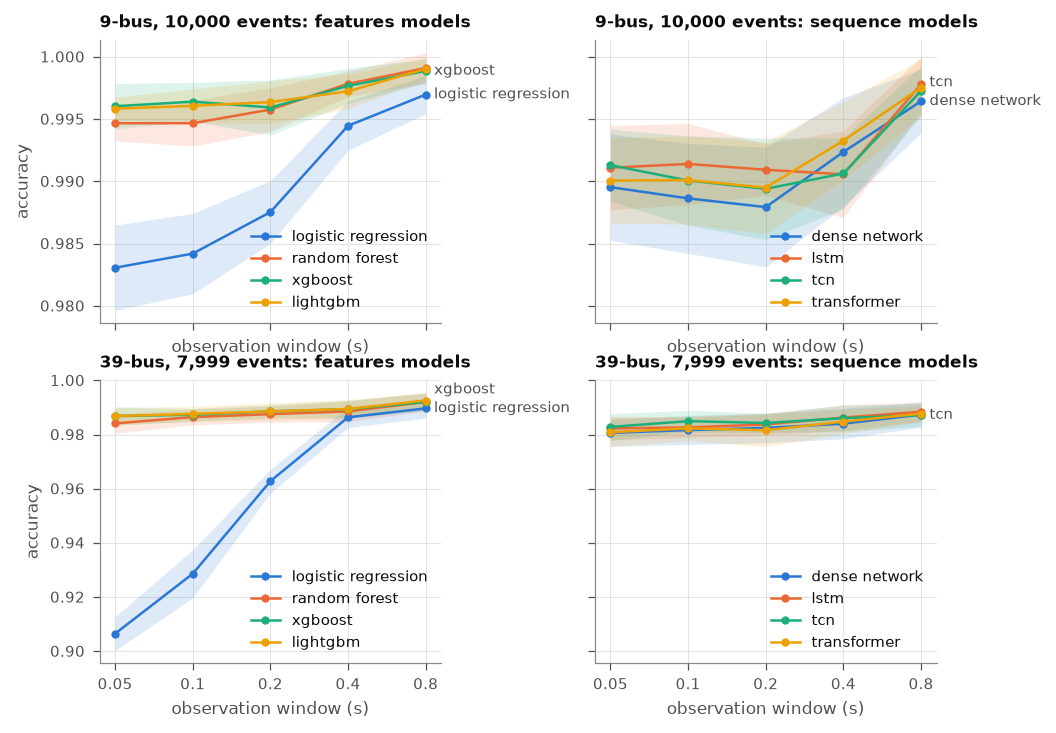

In [9]:
with publication_style():
    fig, axes = plt.subplots(2, 2, figsize=(7.2, 5.4), sharex=True, sharey="row", gridspec_kw={"wspace": 0.45})
    for row, (system, label) in enumerate([("ieee_9bus", "9-bus, 10,000 events"), ("new_england", "39-bus, 7,999 events")]):
        frame = results[system]
        for col, kind in enumerate(("features", "sequence")):
            plot_early_prediction(frame[frame.input == kind], band="ci95", ax=axes[row, col],
                                  title=f"{label}: {kind} models")
            if col:
                axes[row, col].set_ylabel("")
    save_figure(fig, FIGURES / "08_early_prediction_full.pdf")
plt.show()

## Clearing-based windows at full scale

Same folds, windows measured from the detected clearing (non-causal, see docs/validation.md D9).

In [10]:
comparison = []
fast = {k: feature_models[k] for k in ("random forest", "lightgbm")}
for system, manifest in sources.items():
    clear = extract_window_tables(manifest, reference="fault_clear", windows_s=WINDOWS, cache_directory=CACHE)
    for reference, ts in (("fault_start", tables[system]), ("fault_clear", clear)):
        frame = evaluate_window_tables({k: v for k, v in ts.items() if k[1] == "features"}, fast, n_splits=5, n_repeats=3, seed=42,
                                       checkpoint=FIGURES / f"08_{system}_{reference}_comparison.csv")
        comparison.append(frame.assign(system=system, reference=reference))
comparison = pd.concat(comparison)
comparison.pivot_table(index=["system", "model", "window_s"], columns="reference", values="accuracy_mean").round(4)

reference                           fault_clear  fault_start
system      model         window_s                          
ieee_9bus   lightgbm      0.05           0.9995       0.9958
                          0.10           0.9994       0.9961
                          0.20           0.9996       0.9964
                          0.40           0.9998       0.9972
                          0.80           0.9998       0.9990
            random forest 0.05           0.9997       0.9947
                          0.10           0.9996       0.9947
                          0.20           0.9997       0.9958
                          0.40           0.9997       0.9978
                          0.80           0.9999       0.9991
new_england lightgbm      0.05           0.9886       0.9868
                          0.10           0.9891       0.9876
                          0.20           0.9902       0.9886
                          0.40           0.9915       0.9895
                          0.80           0.9937       0.9926
            random forest 0.05           0.9874       0.9841
                          0.10           0.9885       0.9865
                          0.20           0.9887       0.9875
                          0.40           0.9908       0.9885
                          0.80           0.9930       0.9921